# Verification Notebook: Automatic Water-Level Control

This notebook reproduces the analysis and figures in **Chapter 4** and verifies the plant transfer function used in **Chapters 2-5**.

It does four things:

1. Fits the three full-drive calibration runs and recovers `K_hat` and `tau`.
2. Simulates `G(s) = K / (s (tau s + 1))` and checks the analytical step response against `scipy.signal` and an independent RK4 integration of the ODEs.
3. Rebuilds Figure 4.1 and Figure 4.2 in `report/figures/`.
4. Recomputes the 3 cm, 6 cm, and pinched-tube trial statistics from the raw CSV files.

**How to run:** open this notebook from the `project-1` folder tree and choose *Run All*. Required packages: `numpy`, `pandas`, `matplotlib`, and `scipy` (the scipy checks are skipped automatically if it is missing).

The notebook searches upward for the folder containing `data/` and `report/`, so it works whether the working directory is `project-1` or `project-1/analysis`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    from scipy import signal
    HAVE_SCIPY = True
except ImportError:
    HAVE_SCIPY = False

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def find_project_root(start=None):
    """Walk upward until the folder that contains data/ and report/ is found."""
    start = Path.cwd() if start is None else Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "data").is_dir() and (p / "report").is_dir():
            return p
    raise FileNotFoundError("Could not find the project root (expected data/ and report/).")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", ROOT)
print("Data folder  :", DATA_DIR)
print("Figure folder:", FIG_DIR)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("scipy:", "available" if HAVE_SCIPY else "not available (scipy checks will be skipped)")

Project root : /media/rollie/Storage/Documents/obsidian/acads/acads/Feedback/Finals/Project/project-1
Data folder  : /media/rollie/Storage/Documents/obsidian/acads/acads/Feedback/Finals/Project/project-1/data
Figure folder: /media/rollie/Storage/Documents/obsidian/acads/acads/Feedback/Finals/Project/project-1/report/figures
numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2
scipy: available


## 1. Calibration data

The three calibration logs are `test-1.csv`, `test-2.csv`, and `test-3.csv`. Each row is one second of a full-drive run with an empty glass.

`test-2.csv` and `test-3.csv` repeat the current level in two adjacent columns and end with an "Average" text row. The loader below reads only the first numeric time column and the first numeric level column, which removes the text row automatically.

In [2]:
def load_calibration(filename):
    """Read time (s) and level (cm) from one calibration log."""
    df = pd.read_csv(DATA_DIR / filename, header=0)
    t = pd.to_numeric(df.iloc[:, 0], errors="coerce")
    h = pd.to_numeric(df.iloc[:, 1], errors="coerce")
    ok = t.notna() & h.notna()
    return pd.DataFrame({"t_s": t[ok].to_numpy(float), "h_cm": h[ok].to_numpy(float)})


CAL_FILES = ["test-1.csv", "test-2.csv", "test-3.csv"]
cal = {name: load_calibration(name) for name in CAL_FILES}

for name, df in cal.items():
    print(f"{name}: {len(df):2d} samples | "
          f"first = ({df.t_s.iloc[0]:.0f} s, {df.h_cm.iloc[0]:.1f} cm) | "
          f"last = ({df.t_s.iloc[-1]:.0f} s, {df.h_cm.iloc[-1]:.1f} cm)")

test-1.csv: 18 samples | first = (1 s, 1.0 cm) | last = (18 s, 7.3 cm)
test-2.csv: 21 samples | first = (1 s, 0.2 cm) | last = (21 s, 7.2 cm)
test-3.csv: 21 samples | first = (1 s, 0.1 cm) | last = (21 s, 7.2 cm)


In [3]:
def fit_calibration(df):
    t = df["t_s"].to_numpy(float)
    h = df["h_cm"].to_numpy(float)
    m, b = np.polyfit(t, h, 1)          # least-squares line h = m t + b
    pred = m * t + b
    resid = h - pred
    r2 = 1 - np.sum(resid**2) / np.sum((h - h.mean())**2)
    return {
        "n": len(t),
        "final_cm": h[-1],
        "slope_cm_s": m,
        "intercept_cm": b,
        "zero_crossing_s": -b / m,
        "r2": r2,
        "rmse_cm": np.sqrt(np.mean(resid**2)),
    }


fits = {name: fit_calibration(df) for name, df in cal.items()}
cal_table = pd.DataFrame(fits).T
cal_table.index.name = "file"

print("Table 4.1 - calibration fits")
print(cal_table[["n", "final_cm", "slope_cm_s", "intercept_cm",
                 "zero_crossing_s", "r2", "rmse_cm"]].round(5).to_string())

K_hat = float(np.mean([f["slope_cm_s"] for f in fits.values()]))
K_sd = float(np.std([f["slope_cm_s"] for f in fits.values()], ddof=1))
tau_hat = float(np.mean([
    fits["test-2.csv"]["zero_crossing_s"],
    fits["test-3.csv"]["zero_crossing_s"],
]))
endpoint_rates = [
    (df.h_cm.iloc[-1] - df.h_cm.iloc[0]) / (df.t_s.iloc[-1] - df.t_s.iloc[0])
    for df in cal.values()
]

# The report and the controller use the rounded values.
K_model = round(K_hat, 3)
tau_model = round(tau_hat, 2)

print(f"\nIdentified K_hat = {K_hat:.6f} cm/s  (SD {K_sd:.6f})")
print(f"Identified tau   = {tau_hat:.6f} s  (mean of the zero crossings of runs 2 and 3)")
print(f"Average of the three endpoint rates = {np.mean(endpoint_rates):.6f} cm/s")
print(f"\nModel values used in the report: K = {K_model:.3f} cm/s, tau = {tau_model:.2f} s")
print(f"t_run(3 cm) = {3 / K_model:.3f} s | t_run(6 cm) = {6 / K_model:.3f} s")

Table 4.1 - calibration fits
               n  final_cm  slope_cm_s  intercept_cm  zero_crossing_s       r2  rmse_cm
file                                                                                   
test-1.csv  18.0       7.3     0.37079       0.69412         -1.87197  0.99892  0.06313
test-2.csv  21.0       7.2     0.36377      -0.22048          0.60609  0.99842  0.08768
test-3.csv  21.0       7.2     0.36597      -0.26381          0.72084  0.99905  0.06833

Identified K_hat = 0.366845 cm/s  (SD 0.003594)
Identified tau   = 0.663468 s  (mean of the zero crossings of runs 2 and 3)
Average of the three endpoint rates = 0.358529 cm/s

Model values used in the report: K = 0.367 cm/s, tau = 0.66 s
t_run(3 cm) = 8.174 s | t_run(6 cm) = 16.349 s


## 2. Transfer function

The plant is the pump/tubing lag in series with the glass integrator:

    G(s) = K_h / (s (tau s + 1))

The unit-step response, obtained by inverse Laplace transform, is

    h(t) = K_h [ t - tau (1 - exp(-t / tau)) ]

The identified parameters are pooled from the fits above. The report and the controller use the rounded values `K_h = 0.367 cm/s` and `tau = 0.66 s`, so those are the values used for the model checks and the figures.

In [4]:
def G_of_s(s, K=K_model, tau=tau_model):
    """Plant transfer function G(s) = K / (s (tau s + 1))."""
    return K / (s * (tau * s + 1.0))


def h_step(t, K=K_model, tau=tau_model):
    """Analytic unit-step response of G(s), zero initial conditions."""
    t = np.asarray(t, float)
    return K * (t - tau * (1.0 - np.exp(-t / tau)))


print("Plant transfer function")
print(f"  G(s) = {K_model:.6f} / (s * ({tau_model:.6f} s + 1))")
print(f"  numerator   : [{K_model:.6f}]")
print(f"  denominator : [{tau_model:.6f}, 1, 0]   (tau s^2 + s)")

if HAVE_SCIPY:
    G = signal.TransferFunction([K_model], [tau_model, 1.0, 0.0])
    print("\nscipy.signal.TransferFunction")
    print(" ", G)
    print("  poles (rad/s):", np.round(G.poles, 8))

Plant transfer function
  G(s) = 0.367000 / (s * (0.660000 s + 1))
  numerator   : [0.367000]
  denominator : [0.660000, 1, 0]   (tau s^2 + s)

scipy.signal.TransferFunction
  TransferFunctionContinuous(
array([0.55606061]),
array([1.        , 1.51515152, 0.        ]),
dt: None
)
  poles (rad/s): [-1.51515152  0.        ]


## 3. Verifying the transfer function

The check is deliberately redundant:

- **Analytical response** from the inverse Laplace transform.
- **State-space simulation** of the same transfer function with `scipy.signal.step` and `scipy.signal.lsim`.
- **Independent numerical integration** of the two first-order ODEs, `tau dQ/dt + Q = K u` and `dh/dt = Q`, using fixed-step RK4.
- **Integrator-gain check:** a pump pulse of width `t_on` must leave the glass at `K * t_on` after the flow has decayed, independent of `tau`.
- **Fit check:** RMSE between the model and each calibration run.

In [5]:
t_check = np.linspace(0.0, 21.0, 21001)
h_analytic = h_step(t_check)

checks = []

# --- 1. Analytical inverse Laplace vs scipy state-space simulation ---
if HAVE_SCIPY:
    _, h_lsim = signal.step(G, T=t_check)
    checks.append(("max |analytic - scipy lsim| (cm)",
                   float(np.max(np.abs(h_analytic - h_lsim)))))


# --- 2. Independent numerical integration of the two ODEs ---
def rk4_step(t_end, dt=1e-3, K=K_model, tau=tau_model, u=1.0):
    """Integrate tau dQ/dt + Q = K u and dh/dt = Q with fixed-step RK4."""
    n = int(round(t_end / dt)) + 1
    Q = 0.0
    h = 0.0
    ts = np.empty(n)
    hs = np.empty(n)
    for i in range(n):
        ts[i] = i * dt
        hs[i] = h

        def deriv(Q_, h_):
            return (K * u - Q_) / tau, Q_

        k1Q, k1h = deriv(Q, h)
        k2Q, k2h = deriv(Q + 0.5 * dt * k1Q, h + 0.5 * dt * k1h)
        k3Q, k3h = deriv(Q + 0.5 * dt * k2Q, h + 0.5 * dt * k2h)
        k4Q, k4h = deriv(Q + dt * k3Q, h + dt * k3h)
        Q += dt / 6.0 * (k1Q + 2 * k2Q + 2 * k3Q + k4Q)
        h += dt / 6.0 * (k1h + 2 * k2h + 2 * k3h + k4h)
    return ts, hs


t_rk, h_rk = rk4_step(21.0, dt=1e-3)
checks.append(("max |RK4 ODE - analytic| (cm)",
               float(np.max(np.abs(h_rk - h_step(t_rk))))))

# --- 3. Integrator-gain check: a pulse of width t_on must end at K*t_on ---
if HAVE_SCIPY:
    for r in (3.0, 6.0):
        t_on = r / K_model
        T = np.linspace(0.0, t_on + 20 * tau_model, 21001)
        U = (T < t_on).astype(float)
        _, h_pulse, _ = signal.lsim(G, U=U, T=T)
        checks.append((f"pulse {r:.0f} cm: final - K*t_on (cm)",
                       float(h_pulse[-1] - K_model * t_on)))

# --- 4. Model against each calibration run (Run 1 uses its clock shift) ---
for name, df in cal.items():
    shift = 2.6 if name == "test-1.csv" else 0.0
    pred = h_step(df.t_s.to_numpy(float) + shift)
    rmse = np.sqrt(np.mean((df.h_cm.to_numpy(float) - pred) ** 2))
    checks.append((f"RMSE model vs {name} (cm)", float(rmse)))

# --- 5. Crossing times from the transfer function ---
t_3cm = float(np.interp(3.0, h_analytic, t_check))
t_6cm = float(np.interp(6.0, h_analytic, t_check))
checks.append(("time to 3 cm (s)", t_3cm))
checks.append(("time to 6 cm (s)", t_6cm))

check_table = pd.DataFrame(checks, columns=["check", "value"])
print("Transfer-function and model verification")
print(check_table.to_string(index=False, float_format=lambda x: f"{x:.9g}"))

Transfer-function and model verification
                           check           value
max |analytic - scipy lsim| (cm)  2.70450329e-12
   max |RK4 ODE - analytic| (cm)  3.24185123e-13
 pulse 3 cm: final - K*t_on (cm)  0.000109456644
 pulse 6 cm: final - K*t_on (cm) -0.000206600498
   RMSE model vs test-1.csv (cm)    0.0686437868
   RMSE model vs test-2.csv (cm)    0.0897533363
   RMSE model vs test-3.csv (cm)    0.0785785374
                time to 3 cm (s)      8.83438591
                time to 6 cm (s)      17.0087738


## 4. Figure 4.1 - open-loop step response

The figure below is saved to `report/figures/fig-4-1-open-loop-step-response.png` and overwrites the version referenced by Chapter 4.

saved: /media/rollie/Storage/Documents/obsidian/acads/acads/Feedback/Finals/Project/project-1/report/figures/fig-4-1-open-loop-step-response.png


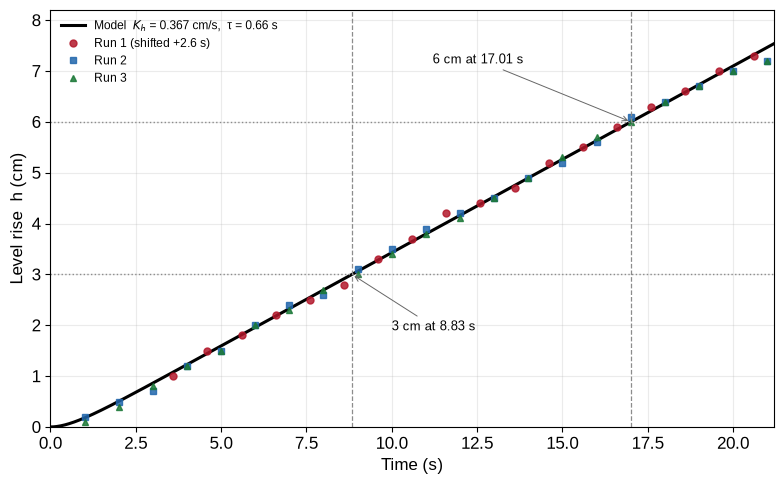

In [6]:
# plt.rcParams.update({"font.family": "Inter", "font.size": 11})

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Noto Sans", "DejaVu Sans"],
    "font.size": 12,
    "mathtext.fontset": "dejavusans",
})

fig, ax = plt.subplots(figsize=(8, 5))
t_plot = np.linspace(0, 21.2, 700)
ax.plot(t_plot, h_step(t_plot), color="black", lw=2.2,
        label=f"Model  $K_h$ = {K_model:.3f} cm/s,  τ = {tau_model:.2f} s")

run_specs = [
    ("Run 1", "test-1.csv", 2.6, "o", "#b2182b"),
    ("Run 2", "test-2.csv", 0.0, "s", "#2166ac"),
    ("Run 3", "test-3.csv", 0.0, "^", "#1b7837"),
]
for label, fname, shift, marker, color in run_specs:
    df = cal[fname]
    ax.plot(df.t_s + shift, df.h_cm, marker, ms=5, color=color, ls="none",
            alpha=0.85,
            label=label + (f" (shifted +{shift:.1f} s)" if shift else ""))

for y in (3, 6):
    ax.axhline(y, color="0.55", ls=":", lw=1)
ax.axvline(t_3cm, color="0.55", ls="--", lw=0.9)
ax.axvline(t_6cm, color="0.55", ls="--", lw=0.9)
ax.annotate(f"3 cm at {t_3cm:.2f} s", xy=(t_3cm, 3), xytext=(10.0, 1.9),
            fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.7, color="0.4"))
ax.annotate(f"6 cm at {t_6cm:.2f} s", xy=(t_6cm, 6), xytext=(11.2, 7.15),
            fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.7, color="0.4"))
ax.set_xlim(0, 21.2)
ax.set_ylim(0, 8.2)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Level rise  h (cm)")
ax.grid(alpha=0.25)
ax.legend(loc="upper left", fontsize=8.5, frameon=False)
fig.tight_layout()

out = FIG_DIR / "fig-4-1-open-loop-step-response.png"
fig.savefig(out, dpi=220)
print("saved:", out)
plt.show()

## 5. Bench trial data

The trial files record two level measurements per run:

- the **Arduino (HC-SR04)** reading, which is what the closed-loop controller acts on;
- the **real rise on the ruler**, which is the ground truth used in the report.

Note: the raw CSV column called `Abs. error (cm)` is actually `|Arduino - ruler|`, not `|real - target|`. The notebook therefore recomputes the control error as `real - target` and keeps the sensor disagreement as a separate diagnostic.

In [7]:
def load_trial_table(filename, target):
    df = pd.read_csv(DATA_DIR / filename)
    df = df[df["Mode"].notna()].copy()
    df["Trial"] = df["Trial"].astype(int)
    numeric_cols = [
        "Battery (V)", "Arduino reading (cm)", "Real rise, ruler (cm)",
        "Abs. error (cm)", "Percent of target",
    ]
    for c in numeric_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["Signed error (cm)"] = df["Real rise, ruler (cm)"] - target
    df["Abs control error (cm)"] = df["Signed error (cm)"].abs()
    df["Percent of target (computed)"] = 100 * df["Real rise, ruler (cm)"] / target
    if "Arduino reading (cm)" in df.columns:
        df["Sensor - ruler (cm)"] = (
            df["Arduino reading (cm)"] - df["Real rise, ruler (cm)"]
        )
    return df


T3 = load_trial_table("3-cm-trial-final.csv", 3.0)
T6 = load_trial_table("6-cm-trial-final.csv", 6.0)
D6 = load_trial_table("6-cm-trial-disturbance.csv", 6.0)


def summarize_trials(df, target):
    g = df.groupby("Mode", sort=False)
    out = pd.DataFrame({
        "mean output (cm)": g["Real rise, ruler (cm)"].mean(),
        "mean signed error (cm)": g["Signed error (cm)"].mean(),
        "mean absolute error (cm)": g["Abs control error (cm)"].mean(),
        "mean percent error (%)": 100 * g["Abs control error (cm)"].mean() / target,
        "SD output (cm)": g["Real rise, ruler (cm)"].std(ddof=1),
    })
    if "Sensor - ruler (cm)" in df.columns:
        out["mean sensor - ruler (cm)"] = g["Sensor - ruler (cm)"].mean()
        out["max |sensor - ruler| (cm)"] = g["Sensor - ruler (cm)"].apply(lambda s: s.abs().max())
    return out


print("3 cm trials")
print(summarize_trials(T3, 3.0).round(4).to_string())
print("\n6 cm trials")
print(summarize_trials(T6, 6.0).round(4).to_string())
print("\n6 cm pinched-tube disturbance")
print(summarize_trials(D6, 6.0).round(4).to_string())

3 cm trials
             mean output (cm)  mean signed error (cm)  mean absolute error (cm)  mean percent error (%)  SD output (cm)  mean sensor - ruler (cm)  max |sensor - ruler| (cm)
Mode                                                                                                                                                                        
Open-loop                3.34                    0.34                    0.3400                 11.3333          0.1442                   -0.1467                       0.30
Closed-loop              3.00                    0.00                    0.1333                  4.4444          0.1732                    0.1433                       0.25

6 cm trials
             mean output (cm)  mean signed error (cm)  mean absolute error (cm)  mean percent error (%)  SD output (cm)  mean sensor - ruler (cm)  max |sensor - ruler| (cm)
Mode                                                                                                          

In [8]:
print("Per-trial control errors (ruler is ground truth)")
for title, df in [("r = 3 cm", T3), ("r = 6 cm", T6)]:
    cols = ["Mode", "Trial", "Battery (V)", "Arduino reading (cm)",
            "Real rise, ruler (cm)", "Signed error (cm)", "Abs control error (cm)"]
    print(f"\n{title}")
    print(df[cols].round(2).to_string(index=False))

print("\nDisturbance trials")
print(D6[["Mode", "Trial", "Real rise, ruler (cm)", "Signed error (cm)",
          "Abs control error (cm)", "Percent of target"]].round(2).to_string(index=False))

print("\nWhy the raw 'Abs. error' column must not be used as the control error")
for title, df in [("3 cm", T3), ("6 cm", T6)]:
    delta = (df["Abs. error (cm)"] - df["Sensor - ruler (cm)"].abs()).abs().max()
    print(f"  {title}: max |raw 'Abs. error' - |Arduino - ruler|| = {delta:.2e} cm")

alpha_ol = D6.loc[D6.Mode == "Open-loop", "Real rise, ruler (cm)"] / 6.0
alpha_mean = float(alpha_ol.mean())
pred_err = 6.0 * (1.0 - alpha_mean)
meas_err = float(D6.loc[D6.Mode == "Open-loop", "Abs control error (cm)"].mean())
print(f"\nDisturbance strength: alpha = {alpha_mean:.4f} "
      f"(trials: {np.round(alpha_ol.to_numpy(), 4)})")
print(f"Predicted open-loop error r(1-alpha) = {pred_err:.4f} cm; "
      f"measured = {meas_err:.4f} cm")

Per-trial control errors (ruler is ground truth)

r = 3 cm
       Mode  Trial  Battery (V)  Arduino reading (cm)  Real rise, ruler (cm)  Signed error (cm)  Abs control error (cm)
  Open-loop      1         5.70                  3.20                   3.50               0.50                    0.50
  Open-loop      2         5.40                  3.19                   3.22               0.22                    0.22
  Open-loop      3         5.78                  3.19                   3.30               0.30                    0.30
Closed-loop      1         5.69                  3.15                   2.90              -0.10                    0.10
Closed-loop      2         5.70                  3.22                   3.20               0.20                    0.20
Closed-loop      3         5.70                  3.06                   2.90              -0.10                    0.10

r = 6 cm
       Mode  Trial  Battery (V)  Arduino reading (cm)  Real rise, ruler (cm)  Signed error 

## 6. Figure 4.2 - measured final levels

Means and error bars are computed from the ruler readings, exactly as in Chapter 4.

saved: /media/rollie/Storage/Documents/obsidian/acads/acads/Feedback/Finals/Project/project-1/report/figures/fig-4-2-measured-final-levels.png


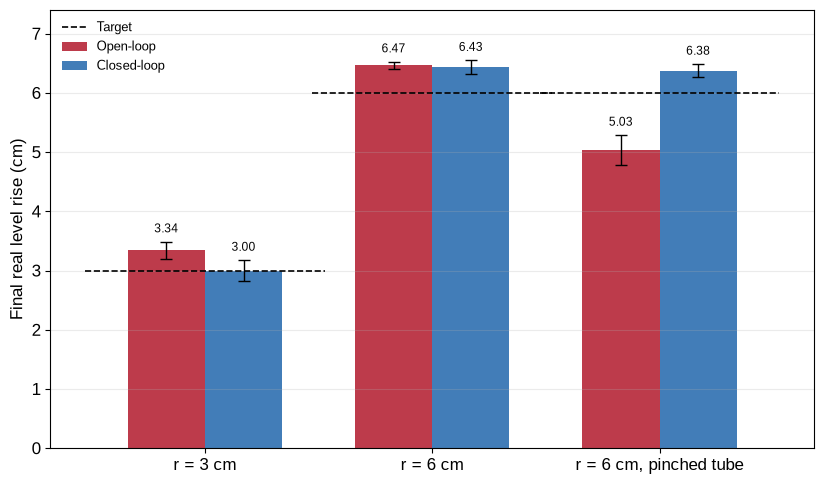

In [9]:
def stats(df):
    ol = df.loc[df.Mode == "Open-loop", "Real rise, ruler (cm)"].to_numpy(float)
    cl = df.loc[df.Mode == "Closed-loop", "Real rise, ruler (cm)"].to_numpy(float)
    return ol.mean(), ol.std(ddof=1), cl.mean(), cl.std(ddof=1)


groups = ["r = 3 cm", "r = 6 cm", "r = 6 cm, pinched tube"]
targets = [3.0, 6.0, 6.0]
s3, s6, sd = stats(T3), stats(T6), stats(D6)
means_ol = np.array([s3[0], s6[0], sd[0]])
sd_ol = np.array([s3[1], s6[1], sd[1]])
means_cl = np.array([s3[2], s6[2], sd[2]])
sd_cl = np.array([s3[3], s6[3], sd[3]])

fig, ax = plt.subplots(figsize=(8.4, 5))
x = np.arange(len(groups))
w = 0.34
ax.bar(x - w / 2, means_ol, w, yerr=sd_ol, capsize=4, color="#b2182b",
       alpha=0.85, label="Open-loop", error_kw=dict(lw=1))
ax.bar(x + w / 2, means_cl, w, yerr=sd_cl, capsize=4, color="#2166ac",
       alpha=0.85, label="Closed-loop", error_kw=dict(lw=1))
for i in range(len(groups)):
    ax.hlines(targets[i], x[i] - w * 1.55, x[i] + w * 1.55,
              colors="black", linestyles="--", lw=1.2,
              label="Target" if i == 0 else None)
    ax.text(x[i] - w / 2, means_ol[i] + sd_ol[i] + 0.16, f"{means_ol[i]:.2f}",
            ha="center", fontsize=8.5)
    ax.text(x[i] + w / 2, means_cl[i] + sd_cl[i] + 0.16, f"{means_cl[i]:.2f}",
            ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("Final real level rise (cm)")
ax.set_ylim(0, 7.4)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()

out = FIG_DIR / "fig-4-2-measured-final-levels.png"
fig.savefig(out, dpi=220)
print("saved:", out)
plt.show()

## 7. Visual verification

The left panel overlays the three independent computations of the step response; they should coincide. The right panel shows the residual of the model against each calibration run, with the ±0.1 cm reading resolution band.

saved: /media/rollie/Storage/Documents/obsidian/acads/acads/Feedback/Finals/Project/project-1/report/figures/fig-model-verification.png


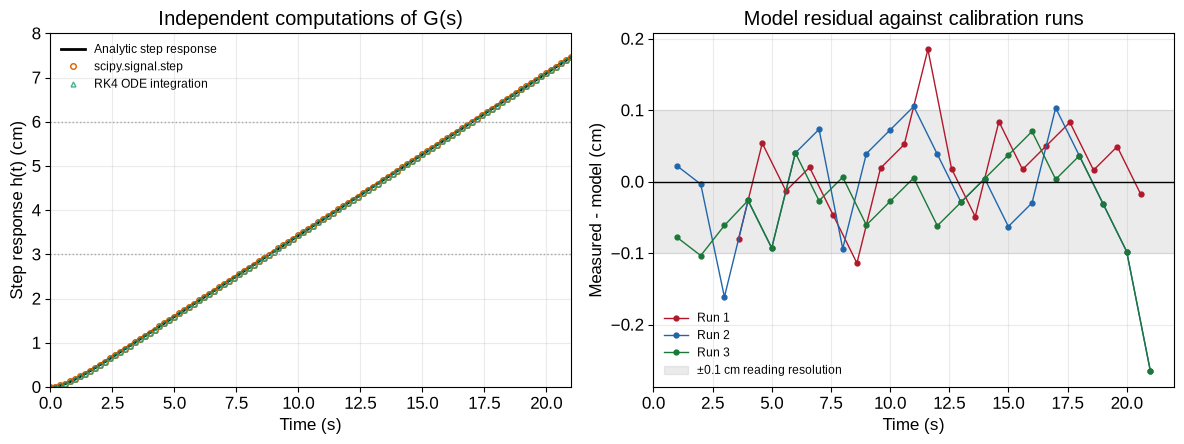

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# Left: the three independent computations should lie on top of each other.
ax = axes[0]
ax.plot(t_check, h_analytic, color="black", lw=2.0, label="Analytic step response")
if HAVE_SCIPY:
    ax.plot(t_check[::200], h_lsim[::200], "o", ms=4, mfc="none",
            mec="#d95f02", label="scipy.signal.step")
ax.plot(t_rk[::200], h_rk[::200], "^", ms=3.5, mfc="none",
        mec="#1b9e77", alpha=0.8, label="RK4 ODE integration")
ax.axhline(3, color="0.65", ls=":", lw=1)
ax.axhline(6, color="0.65", ls=":", lw=1)
ax.set_xlim(0, 21)
ax.set_ylim(0, 8)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Step response h(t) (cm)")
ax.set_title("Independent computations of G(s)")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8.5)

# Right: residuals of the model against each calibration run.
ax = axes[1]
for label, fname, shift, color in [
    ("Run 1", "test-1.csv", 2.6, "#b2182b"),
    ("Run 2", "test-2.csv", 0.0, "#2166ac"),
    ("Run 3", "test-3.csv", 0.0, "#1b7837"),
]:
    df = cal[fname]
    resid = df.h_cm.to_numpy(float) - h_step(df.t_s.to_numpy(float) + shift)
    ax.plot(df.t_s + shift, resid, "o-", ms=3.5, lw=1, color=color, label=label)
ax.axhline(0, color="black", lw=1)
ax.axhspan(-0.1, 0.1, color="0.7", alpha=0.25,
           label="±0.1 cm reading resolution")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Measured - model (cm)")
ax.set_title("Model residual against calibration runs")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8.5)

fig.tight_layout()
out = FIG_DIR / "fig-model-verification.png"
fig.savefig(out, dpi=220)
print("saved:", out)
plt.show()

## 8. Summary

The values below should reproduce the key numbers in Chapters 4 and 5.

In [11]:
def mae(df, mode):
    return float(df.loc[df.Mode == mode, "Abs control error (cm)"].mean())


rows = [
    ("Identified K_hat", f"{K_hat:.4f} ± {K_sd:.4f} cm/s"),
    ("Identified tau", f"{tau_hat:.3f} s"),
    ("Model used in report", f"G(s) = {K_model:.3f} / (s({tau_model:.2f}s + 1))"),
    ("Time to 3 cm", f"{t_3cm:.2f} s"),
    ("Time to 6 cm", f"{t_6cm:.2f} s"),
    ("Open-loop error, 3 cm", f"{mae(T3, 'Open-loop'):.3f} cm ({100 * mae(T3, 'Open-loop') / 3:.1f}%)"),
    ("Closed-loop error, 3 cm", f"{mae(T3, 'Closed-loop'):.3f} cm ({100 * mae(T3, 'Closed-loop') / 3:.1f}%)"),
    ("Open-loop error, 6 cm", f"{mae(T6, 'Open-loop'):.3f} cm ({100 * mae(T6, 'Open-loop') / 6:.1f}%)"),
    ("Closed-loop error, 6 cm", f"{mae(T6, 'Closed-loop'):.3f} cm ({100 * mae(T6, 'Closed-loop') / 6:.1f}%)"),
    ("Open-loop error, pinched 6 cm", f"{mae(D6, 'Open-loop'):.3f} cm ({100 * mae(D6, 'Open-loop') / 6:.1f}%)"),
    ("Closed-loop error, pinched 6 cm", f"{mae(D6, 'Closed-loop'):.3f} cm ({100 * mae(D6, 'Closed-loop') / 6:.1f}%)"),
    ("Disturbance alpha", f"{alpha_mean:.3f}"),
    ("Predicted r(1-alpha)", f"{pred_err:.3f} cm"),
]
print(pd.DataFrame(rows, columns=["quantity", "value"]).to_string(index=False))

                       quantity                         value
               Identified K_hat          0.3668 ± 0.0036 cm/s
                 Identified tau                       0.663 s
           Model used in report G(s) = 0.367 / (s(0.66s + 1))
                   Time to 3 cm                        8.83 s
                   Time to 6 cm                       17.01 s
          Open-loop error, 3 cm              0.340 cm (11.3%)
        Closed-loop error, 3 cm               0.133 cm (4.4%)
          Open-loop error, 6 cm               0.467 cm (7.8%)
        Closed-loop error, 6 cm               0.433 cm (7.2%)
  Open-loop error, pinched 6 cm              0.967 cm (16.1%)
Closed-loop error, pinched 6 cm               0.377 cm (6.3%)
              Disturbance alpha                         0.839
           Predicted r(1-alpha)                      0.967 cm
